# Data Analysis: Data Visualisation Principles and Storytelling

> **Who is this for:** anyone who can already make charts with matplotlib, seaborn or Plotly and now wants to make charts that are **correct, clear and convincing**: the difference between "a chart" and "a chart a manager acts on". Also for BS Data Science "Data Visualization" courses and for analyst interviews ("what is wrong with this chart?").
>
> **What you will learn:**
> - **perception**: pre-attentive attributes, the **Cleveland–McGill** ranking of visual encodings, the **data-ink ratio**
> - how to **choose a chart by the question** (comparison, distribution, composition, relationship, change over time)
> - **common lies and mistakes** (truncated axes, dual axes, pie abuse, rainbow colour maps, area scaling) with before/after fixes
> - **colour**: categorical vs sequential vs diverging; **colour-blind-safe** palettes, checked by simulating colour-vision deficiency and computing contrast **from scratch**
> - **annotation and narrative**: titles that state the insight, highlighting, small multiples, the "Big Idea" and a storyboard
> - **uncertainty visualisation**: error bars, intervals, fan charts, hypothetical-outcome plots
> - a **KPI dashboard in Plotly** exported as a standalone HTML file, and how the same ideas appear in **Power BI / Tableau**
> - an industry mini-case: the findings of the [stakeholder EDA report](11_industry_eda_report_for_stakeholders.ipynb) told as a **5-chart executive story**
>
> **Prerequisites:** [matplotlib](04_matplotlib.ipynb), [seaborn](05_seaborn.ipynb), [Plotly](06_plotly.ipynb), [EDA](07_eda.ipynb). Recommended: [the industry EDA report](11_industry_eda_report_for_stakeholders.ipynb) (we reuse its findings).
>
> **Time needed:** about 2 to 3 hours.
>
> **Runs on:** CPU, no API key, no internet (the dashboard HTML is written to a temporary folder).
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

A chart is a picture that helps someone **understand numbers quickly**. Our eyes are very good at some things (comparing the lengths of bars that start at the same line, spotting the one red dot among grey ones) and bad at others (comparing angles in a pie, comparing areas of circles). A good chart uses what eyes are good at, removes everything that does not help, and says its **message in the title**. A bad chart can even **lie** by accident: if a bar chart starts at 95 instead of 0, a 2% difference looks like a 200% difference. Colour must be chosen carefully too, because about 1 in 12 men (and 1 in 200 women) cannot tell some colours apart. Finally, numbers are uncertain, and an honest chart shows that uncertainty instead of hiding it.

**Everyday examples:**
- A **weather app** shows tomorrow's temperature as a line and the chance of rain as a shaded band: one look, no table reading. The band is uncertainty visualisation.
- A **fuel gauge** in a car is a tiny dashboard: one number that matters, shown big, with a red zone that needs no explanation.
- A **news chart** titled "Prices rose faster than wages for the third year" tells you what to look for; a chart titled "Prices and wages, 2020–2026" makes you do the work.

**Tiny example:** two shops sold 98 and 100 cakes. Drawn as bars starting at 0, the bars look almost equal (true: 2% difference). Drawn with the axis starting at 97, the second bar looks **3 times** as tall as the first (1 unit vs 3 units above 97). Same data, opposite impressions.

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Encoding ranking (position > length > angle > area > colour) | use the visual channel eyes judge best for the most important comparison | every dashboard, scientific paper and news graphic |
| Colour-blind-safe palettes | colours that stay distinguishable for everyone | maps, traffic-light status, ML confusion-matrix heatmaps |
| Story and uncertainty | one clear message per chart, with honest error bands | executive reports, forecasts, ML model comparisons with confidence intervals |

### How this notebook is different from its neighbours

| Notebook | Focus |
|---|---|
| [04_matplotlib](04_matplotlib.ipynb), [05_seaborn](05_seaborn.ipynb), [06_plotly](06_plotly.ipynb) | **how** to draw charts with each library (API, chart types) |
| [07_eda](07_eda.ipynb) | charts for **exploring** data yourself |
| [11_industry_eda_report_for_stakeholders](11_industry_eda_report_for_stakeholders.ipynb) | the analysis behind a stakeholder report |
| **This notebook** | **why** some charts work and others mislead; colour science; storytelling; uncertainty; dashboards |

## 0. Setup

We use one consistent, colour-blind-checked categorical palette (`PALETTE`, the same one every notebook in this track uses), always **in the same order**, and grey for "everything else".

In [1]:
# Standard setup used throughout this notebook
import random, math, time, timeit, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import os, tempfile, shutil
import matplotlib as mpl
import matplotlib.ticker as mticker
from matplotlib.colors import to_rgb
from scipy import stats
GREY, INK, MUTED = "#b4b2a9", "#0b0b0b", "#52514e"          # neutral for de-emphasis, text colours
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]   # one-hue ramp
DIV_NEUTRAL = "#f0efec"                                       # grey midpoint for diverging scales
WORK = tempfile.mkdtemp(prefix="viz_")
print("matplotlib", mpl.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


matplotlib 3.11.0


---
## 1. Perception basics

> 💬 **In plain English:** use what eyes are good at (lengths and positions on a shared line) and remove everything that does not help.

### 1.1 Pre-attentive attributes

Some visual differences are noticed in a fraction of a second, **before** conscious attention ("pre-attentive" processing): **colour hue**, **intensity**, **size**, **orientation**, **shape**, **enclosure**, **position**. Use them to make the important thing pop out. But a target defined by a **combination** (red **and** square) is not pre-attentive: you must search item by item.

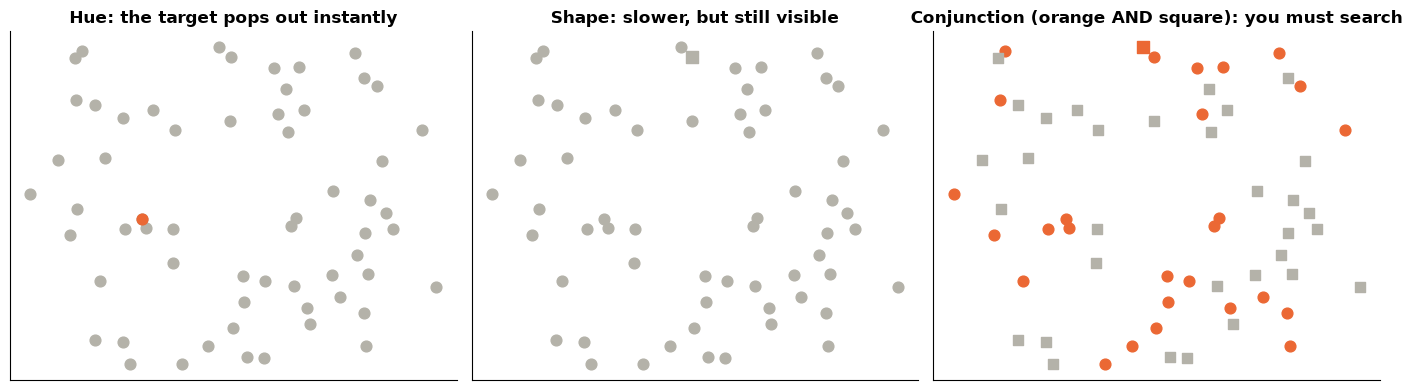

In [2]:
rng = np.random.default_rng(1)
xy = rng.uniform(0, 1, (60, 2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax in axes:
    ax.set(xticks=[], yticks=[]); ax.grid(False)
# (a) colour pop-out
axes[0].scatter(xy[:, 0], xy[:, 1], s=60, color=GREY)
axes[0].scatter(*xy[7], s=60, color=PALETTE[1])
axes[0].set_title("Hue: the target pops out instantly")
# (b) shape pop-out
axes[1].scatter(xy[1:, 0], xy[1:, 1], s=60, color=GREY, marker="o")
axes[1].scatter(*xy[0], s=70, color=GREY, marker="s")
axes[1].set_title("Shape: slower, but still visible")
# (c) conjunction: find the orange SQUARE among orange circles and grey squares
kinds = rng.integers(0, 2, 60)
for k, (col, mk) in enumerate([(PALETTE[1], "o"), (GREY, "s")]):
    pts = xy[kinds == k]
    axes[2].scatter(pts[:, 0], pts[:, 1], s=60, color=col, marker=mk)
axes[2].scatter(*xy[11], s=70, color=PALETTE[1], marker="s")
axes[2].set_title("Conjunction (orange AND square): you must search")
plt.tight_layout(); plt.show()

**Lesson:** use **one** pre-attentive attribute (usually colour against grey) to point at the message. If everything is coloured, nothing stands out.

### 1.2 The Cleveland–McGill ranking of encodings

Cleveland & McGill (1984, *JASA*) measured how accurately people judge quantities shown with different visual **encodings**. Their ranking (most to least accurate), later confirmed by crowdsourced replications (Heer & Bostock, 2010):

| Rank | Encoding | Typical chart |
|---|---|---|
| 1 | **Position on a common scale** | dot plot, bar chart (bar ends), scatter |
| 2 | Position on non-aligned scales | small multiples with separate axes |
| 3 | **Length** | bars, stacked-bar segment lengths |
| 4 | Direction / slope | line chart slopes |
| 5 | **Angle** | pie chart |
| 6 | **Area** | bubbles, treemaps |
| 7 | Volume | 3-D charts |
| 8 | Colour saturation / shading | heatmaps, choropleth maps |

So: put the **most important comparison** on the **best** channel (position/length), and use colour for categories or for heatmaps where position is already used.

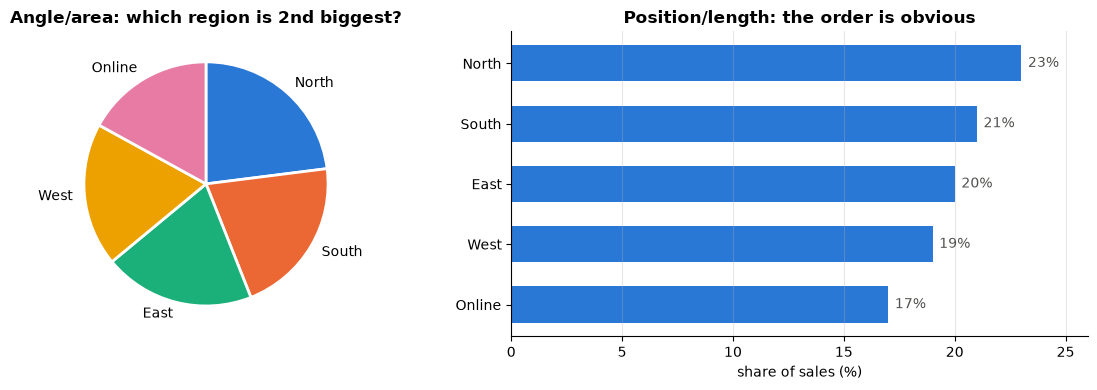

In [3]:
shares = pd.Series({"North": 23, "South": 21, "East": 20, "West": 19, "Online": 17})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].pie(shares, labels=shares.index, colors=PALETTE[:5], startangle=90, counterclock=False,
            wedgeprops={"linewidth": 2, "edgecolor": "white"})
axes[0].set_title("Angle/area: which region is 2nd biggest?")
s = shares.sort_values()
axes[1].barh(s.index, s.to_numpy(), color=PALETTE[0], height=0.6)
for i, v in enumerate(s.to_numpy()):
    axes[1].text(v + 0.3, i, f"{v}%", va="center", color=MUTED)
axes[1].set(title="Position/length: the order is obvious", xlabel="share of sales (%)", xlim=(0, 26))
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**What just happened?** The five shares (23, 21, 20, 19, 17%) are almost impossible to rank in the pie, but trivial in the sorted bar chart. Pies are acceptable only for **2–3 parts** of a whole when the message is "about a half" or "about a quarter".

### 1.3 Data-ink ratio

Edward Tufte (*The Visual Display of Quantitative Information*, 1983) defines the **data-ink ratio** = ink that shows data ÷ total ink. Maximise it within reason: remove heavy grids, borders, backgrounds, 3-D effects, redundant legends and decorations ("**chartjunk**"); keep what helps reading (light gridlines, a few labels).

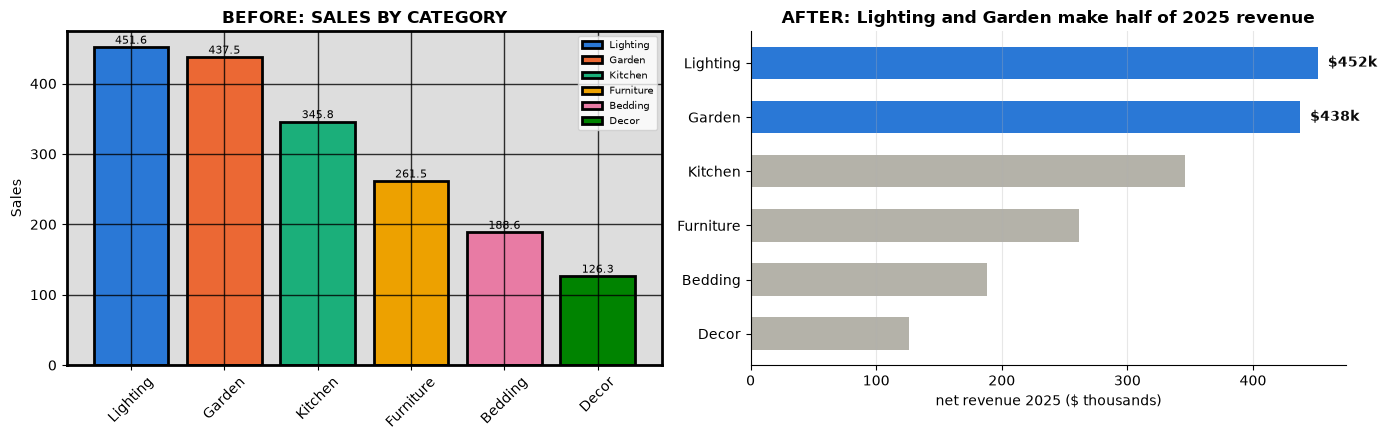

In [4]:
sales = pd.Series({"Lighting": 451.6, "Garden": 437.5, "Kitchen": 345.8, "Furniture": 261.5, "Bedding": 188.6, "Decor": 126.3})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# BEFORE: background, heavy grid, one colour per bar (meaningless), legend repeating the axis, border, values everywhere
ax = axes[0]
ax.set_facecolor("#dddddd")
bars = ax.bar(sales.index, sales.to_numpy(), color=PALETTE[:6], edgecolor="black", linewidth=2, label=sales.index)
ax.grid(True, color="black", linewidth=1, alpha=0.8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(True)
for spine in ax.spines.values():
    spine.set_linewidth(2)
for b_ in bars:
    ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 5, f"{b_.get_height():.1f}", ha="center", fontsize=8)
ax.legend(handles=list(bars), labels=list(sales.index), fontsize=7, loc="upper right")
ax.set(title="BEFORE: SALES BY CATEGORY", ylabel="Sales")
ax.tick_params(axis="x", rotation=45)
# AFTER: sorted, one colour, horizontal for readable labels, light grid, highlight the message
ax = axes[1]
s = sales.sort_values()
colors = [PALETTE[0] if c in ("Lighting", "Garden") else GREY for c in s.index]
ax.barh(s.index, s.to_numpy(), color=colors, height=0.6)
ax.grid(axis="y", visible=False)
for i, (c, v) in enumerate(s.items()):
    if c in ("Lighting", "Garden"):
        ax.text(v + 8, i, f"${v:.0f}k", va="center", color=INK, fontweight="bold")
ax.set(title="AFTER: Lighting and Garden make half of 2025 revenue", xlabel="net revenue 2025 ($ thousands)")
plt.tight_layout(); plt.show()

**What just happened?** The "after" chart has less ink but more information: it is sorted, uses one colour (the six bars are one series, so different colours would suggest a meaning that does not exist), highlights the two categories the message is about, and the title states the insight (Lighting + Garden = 451.6 + 437.5 of 1,811.3 = 49%).

---
## 2. Choosing the chart by the question

> 💬 **In plain English:** first ask what question the reader has, then pick the chart that answers it.

Start from the **question** the reader has, not from the chart types a library offers.

| Question | Data job | Good choices | Avoid |
|---|---|---|---|
| **Comparison**: which is bigger? | magnitude across categories | sorted bar / dot plot | pie, radar, 3-D bars |
| **Distribution**: how are values spread? | shape, centre, outliers | histogram, box/violin plot, ECDF, strip plot | bar of means only |
| **Composition**: what are the parts of the whole? | part-to-whole | stacked bar (≤ 5 parts), 100% bar, waterfall (for changes), treemap | pie with many slices |
| **Relationship**: does X go with Y? | correlation, clusters | scatter (+ trend line), hexbin for many points, heatmap of a correlation matrix | two lines on dual axes |
| **Change over time**: how did it evolve? | trend, seasonality | line chart, slope chart (2 time points), area (only for one or stacked totals) | bars for long daily series, pie per year |
| **Ranking** | order | sorted bars, dot plot, bump chart | unsorted bars |
| **One number** | a headline | big number ("stat tile") with comparison | a one-bar chart |

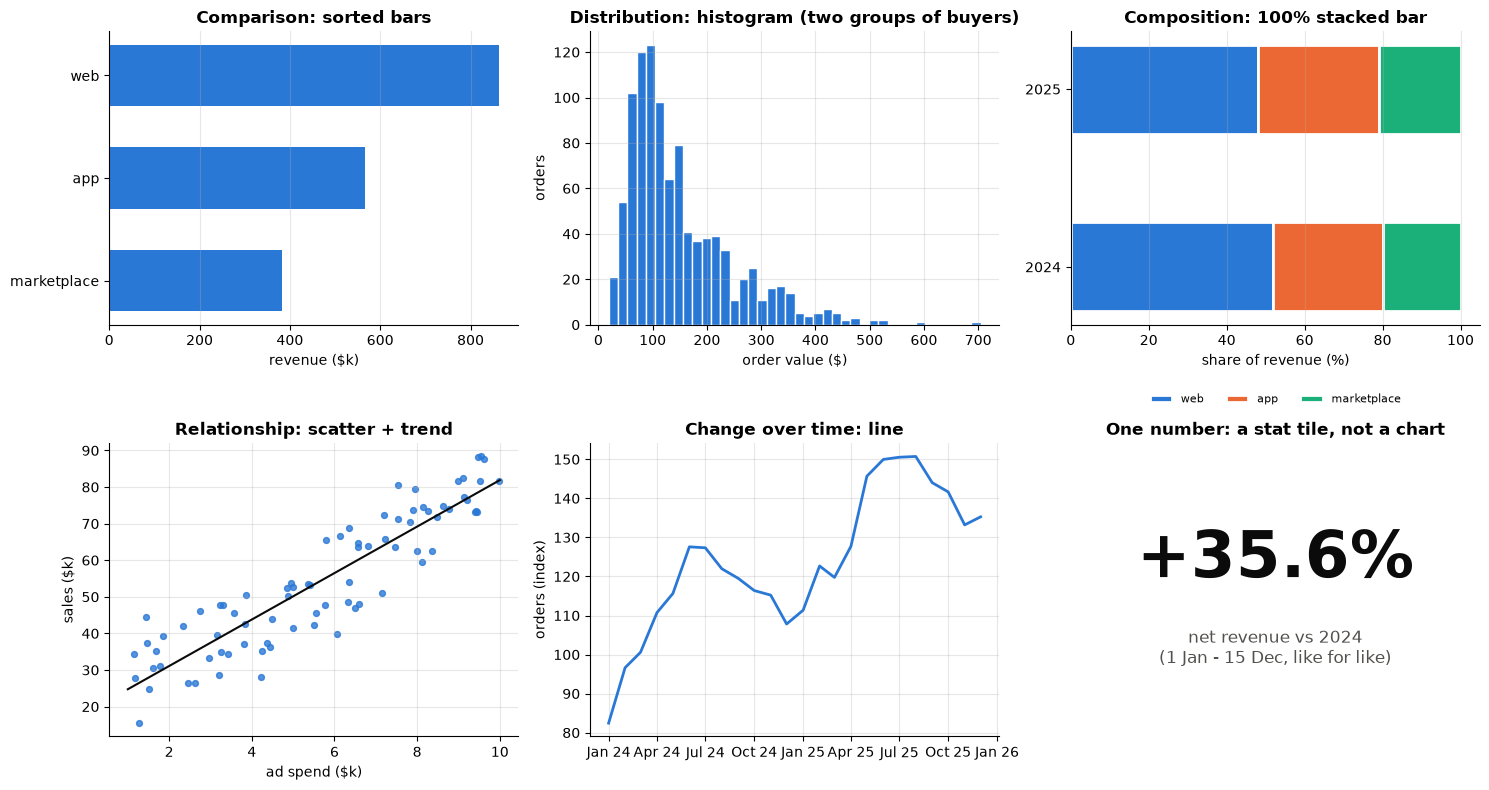

In [5]:
rng = np.random.default_rng(3)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
# Comparison
v = pd.Series({"web": 862.8, "app": 565.9, "marketplace": 382.5}).sort_values()
axes[0, 0].barh(v.index, v.to_numpy(), color=PALETTE[0], height=0.6); axes[0, 0].grid(axis="y", visible=False)
axes[0, 0].set(title="Comparison: sorted bars", xlabel="revenue ($k)")
# Distribution
x = np.concatenate([rng.lognormal(4.6, 0.5, 800), rng.lognormal(5.6, 0.3, 200)])
axes[0, 1].hist(x, bins=40, color=PALETTE[0], edgecolor="white")
axes[0, 1].set(title="Distribution: histogram (two groups of buyers)", xlabel="order value ($)", ylabel="orders")
# Composition
comp = pd.DataFrame({"web": [52, 48], "app": [28, 31], "marketplace": [20, 21]}, index=["2024", "2025"])
left = np.zeros(2)
for i, col in enumerate(comp.columns):
    axes[0, 2].barh(comp.index, comp[col], left=left, color=PALETTE[i], label=col, height=0.5, edgecolor="white", linewidth=2)
    left += comp[col].to_numpy()
axes[0, 2].set(title="Composition: 100% stacked bar", xlabel="share of revenue (%)")
axes[0, 2].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
axes[0, 2].grid(axis="y", visible=False)
# Relationship
ad = rng.uniform(1, 10, 80); sales_ = 20 + 6 * ad + rng.normal(0, 8, 80)
axes[1, 0].scatter(ad, sales_, s=18, color=PALETTE[0], alpha=0.8)
k, c0 = np.polyfit(ad, sales_, 1); xs = np.linspace(1, 10, 2)
axes[1, 0].plot(xs, c0 + k * xs, color=INK, lw=1.5)
axes[1, 0].set(title="Relationship: scatter + trend", xlabel="ad spend ($k)", ylabel="sales ($k)")
# Change over time
months = pd.date_range("2024-01-01", periods=24, freq="MS")
trend = 100 + np.arange(24) * 2 + 15 * np.sin(np.arange(24) / 12 * 2 * np.pi - 1.4) + rng.normal(0, 4, 24)
axes[1, 1].plot(months, trend, color=PALETTE[0])
axes[1, 1].set(title="Change over time: line", ylabel="orders (index)")
axes[1, 1].xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %y"))
# One number
axes[1, 2].axis("off")
axes[1, 2].text(0.5, 0.6, "+35.6%", ha="center", va="center", fontsize=46, fontweight="bold", color=INK)
axes[1, 2].text(0.5, 0.3, "net revenue vs 2024\n(1 Jan - 15 Dec, like for like)", ha="center", va="center", fontsize=12, color=MUTED)
axes[1, 2].set_title("One number: a stat tile, not a chart")
plt.tight_layout(); plt.show()

---
## 3. Common lies and mistakes, with fixes

> 💬 **In plain English:** small drawing choices (where an axis starts, two y-axes, circle sizes) can make a chart lie; here is how to fix them.

Most misleading charts are accidents. Tufte's **lie factor** measures the distortion:

$$\text{Lie factor} = \frac{\text{size of effect shown in the graphic}}{\text{size of effect in the data}}$$

A value near 1 is honest; above about 1.05 or below 0.95 is a substantial distortion.

### 3.1 Truncated axes on bar charts
A bar encodes a value by its **length**, so its baseline must be **0**. (Line charts and dot plots encode by **position** and may zoom in, as long as the axis is clearly labelled.)

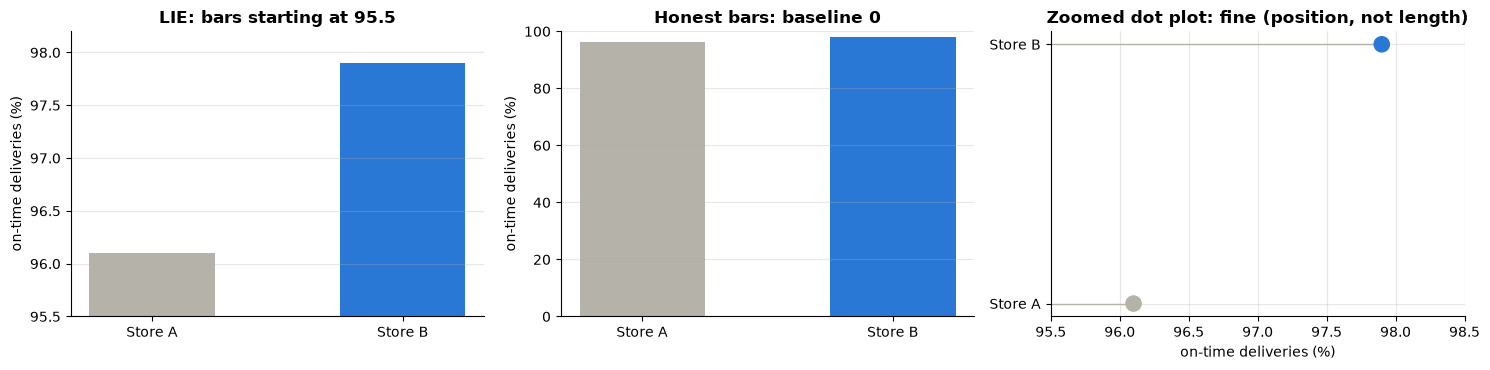

Truncated chart shows B 300% longer; the data say 1.9% higher -> lie factor 160


In [6]:
sat = pd.Series({"Store A": 96.1, "Store B": 97.9})
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(sat.index, sat.to_numpy(), color=[GREY, PALETTE[0]], width=0.5)
axes[0].set_ylim(95.5, 98.2); axes[0].set(title="LIE: bars starting at 95.5", ylabel="on-time deliveries (%)")
axes[1].bar(sat.index, sat.to_numpy(), color=[GREY, PALETTE[0]], width=0.5)
axes[1].set_ylim(0, 100); axes[1].set(title="Honest bars: baseline 0", ylabel="on-time deliveries (%)")
axes[2].scatter(sat.to_numpy(), sat.index, s=120, color=[GREY, PALETTE[0]], zorder=3)
axes[2].hlines(sat.index, 95.5, sat.to_numpy(), color=GREY, lw=1)
axes[2].set_xlim(95.5, 98.5); axes[2].set(title="Zoomed dot plot: fine (position, not length)", xlabel="on-time deliveries (%)")
for ax in axes[:2]:
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

shown = (sat["Store B"] - 95.5) / (sat["Store A"] - 95.5) - 1            # bar-length ratio in the truncated chart
actual = sat["Store B"] / sat["Store A"] - 1
print(f"Truncated chart shows B {100 * shown:.0f}% longer; the data say {100 * actual:.1f}% higher -> lie factor {shown / actual:.0f}")

### 3.2 Dual axes
Two y-axes with independent scales let the chart-maker make **any** two series look correlated or uncorrelated, simply by choosing the ranges. Fix: two aligned charts (small multiples) or **index both series to 100** at the start, on one axis.

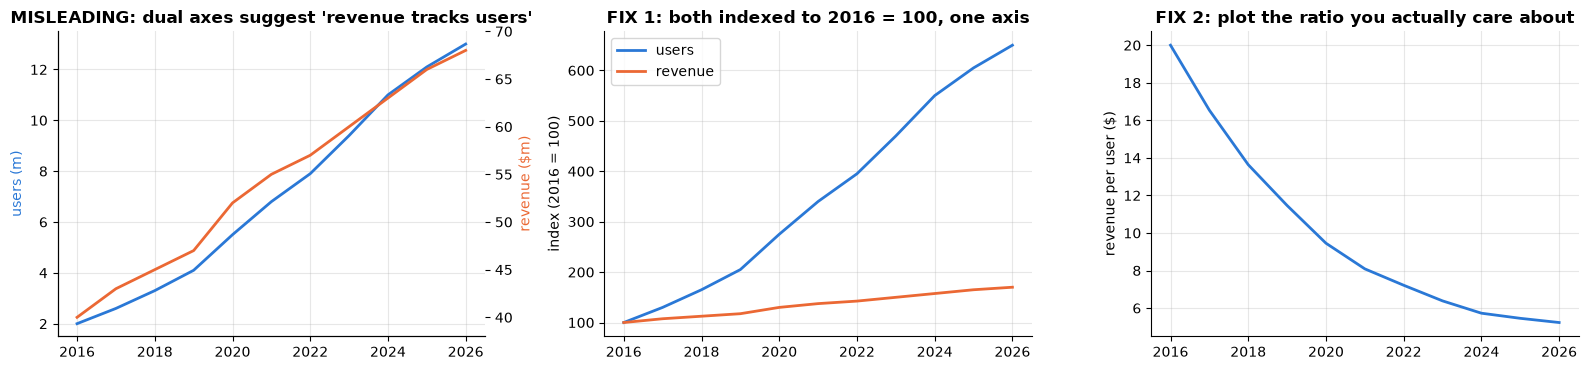

2016 -> 2026: users x6.5, revenue x1.70, revenue per user $20 -> $5.23


In [7]:
yrs = np.arange(2016, 2027)
users = np.array([2.0, 2.6, 3.3, 4.1, 5.5, 6.8, 7.9, 9.4, 11.0, 12.1, 13.0])          # millions
revenue = np.array([40, 43, 45, 47, 52, 55, 57, 60, 63, 66, 68])                     # $ millions
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
ax = axes[0]; ax2 = ax.twinx()
ax.plot(yrs, users, color=PALETTE[0]); ax2.plot(yrs, revenue, color=PALETTE[1])
ax2.set_ylim(38, 70); ax.set_ylim(1.5, 13.5)
ax.set(title="MISLEADING: dual axes suggest 'revenue tracks users'"); ax.set_ylabel("users (m)", color=PALETTE[0]); ax2.set_ylabel("revenue ($m)", color=PALETTE[1])
ax2.grid(False)
axes[1].plot(yrs, 100 * users / users[0], color=PALETTE[0], label="users")
axes[1].plot(yrs, 100 * revenue / revenue[0], color=PALETTE[1], label="revenue")
axes[1].set(title="FIX 1: both indexed to 2016 = 100, one axis", ylabel="index (2016 = 100)"); axes[1].legend()
axes[2].plot(yrs, revenue / users, color=PALETTE[0])
axes[2].set(title="FIX 2: plot the ratio you actually care about", ylabel="revenue per user ($)")
plt.tight_layout(); plt.show()
print(f"2016 -> 2026: users x{users[-1] / users[0]:.1f}, revenue x{revenue[-1] / revenue[0]:.2f}, revenue per user ${revenue[0] / users[0]:.0f} -> ${revenue[-1] / users[-1]:.2f}")

**What just happened?** The dual-axis chart makes two curves look like they move together. Indexed to a common base, the truth appears: users grew 6.5-fold while revenue grew only 1.7-fold, so **revenue per user fell sharply**, the opposite of the impression the first chart gives.

### 3.3 Pie abuse and area scaling
Pies with many slices, exploded or 3-D pies, and several pies side by side for comparison all fail the angle/area problem. A related lie: scaling a **circle's radius** (or an icon's height and width) with the value, so the **area** grows with the square.

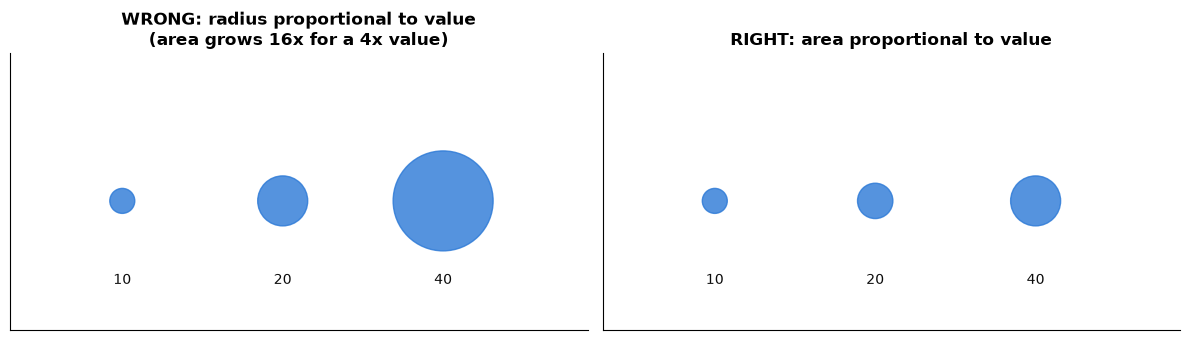

Lie factor of radius scaling for 10 -> 40: area ratio 16 / value ratio 4 = 4


In [8]:
vals = np.array([10, 20, 40])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, title, size_rule in [(axes[0], "WRONG: radius proportional to value\n(area grows 16x for a 4x value)", lambda v: (v / vals[0] * 18) ** 2),
                             (axes[1], "RIGHT: area proportional to value", lambda v: (v / vals[0]) * 18 ** 2)]:
    ax.scatter([1, 2, 3], [1, 1, 1], s=size_rule(vals), color=PALETTE[0], alpha=0.8)
    for xx, v in zip([1, 2, 3], vals):
        ax.text(xx, 0.55, f"{v}", ha="center", color=INK)
    ax.set(xlim=(0.3, 3.9), ylim=(0.3, 1.8), xticks=[], yticks=[], title=title); ax.grid(False)
plt.tight_layout(); plt.show()
print(f"Lie factor of radius scaling for 10 -> 40: area ratio {(40 / 10) ** 2:.0f} / value ratio {40 / 10:.0f} = {(40 / 10) ** 2 / (40 / 10):.0f}")

### 3.4 Rainbow colour maps
The classic "jet"/rainbow colour map has **non-monotonic lightness**: it gets brighter and darker several times, so readers see sharp "edges" (yellow and cyan bands) that are not in the data, and it is unreadable in greyscale and for colour-blind readers. **Perceptually uniform** maps such as `viridis` (the matplotlib default since 2.0) increase lightness steadily. We measure lightness with the **OKLab** colour space (Ottosson, 2020), which we implement in Section 4.

---
## 4. Colour: types of scales, colour-blind safety, contrast

> 💬 **In plain English:** pick colours by their job, and check with simple maths that everyone, including colour-blind readers, can tell them apart.

### 4.1 Three jobs for colour
| Job | Data | Rule | Example |
|---|---|---|---|
| **Categorical** (identity) | unordered groups | distinct hues, **fixed order**, ≤ 7–8 colours; fold the rest into "Other" | channels, models, countries |
| **Sequential** (magnitude) | ordered, low → high | **one hue**, light → dark (or a perceptually uniform map) | revenue per region, a heatmap of counts |
| **Diverging** (polarity) | deviation from a meaningful midpoint (0, target, average) | **two opposite hues** + a **neutral grey** midpoint | growth vs last year, correlation matrix |

And keep colours **attached to entities**: if "marketplace" is orange in one chart, it is orange in every chart, even when filtered.

### 4.2 Colour-vision deficiency (CVD), simulated from scratch

About **8% of men and 0.5% of women** of Northern European descent have a red–green colour-vision deficiency (protan or deutan types); tritan (blue–yellow) types are rare. We can **simulate** how a colour looks to them with the matrices of Machado, Oliveira & Fernandes (2009), then measure the difference between two colours as a distance in the perceptually uniform **OKLab** space (ΔE; here scaled ×100, so about 2 is barely noticeable and ≥ 8 is comfortably distinct for chart colours).

Pipeline per colour: hex → sRGB (0–1) → **linear** RGB (undo gamma) → apply the CVD matrix → OKLab → ΔE between pairs.

In [9]:
def srgb_to_linear(c):
    c = np.asarray(c, float)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def linear_to_oklab(rgb):
    """Linear sRGB (..., 3) -> OKLab (..., 3) (Ottosson 2020)."""
    M1 = np.array([[0.4122214708, 0.5363325363, 0.0514459929],
                   [0.2119034982, 0.6806995451, 0.1073969566],
                   [0.0883024619, 0.2817188376, 0.6299787005]])
    M2 = np.array([[0.2104542553, 0.7936177850, -0.0040720468],
                   [1.9779984951, -2.4285922050, 0.4505937099],
                   [0.0259040371, 0.7827717662, -0.8086757660]])
    lms = np.cbrt(np.asarray(rgb) @ M1.T)
    return lms @ M2.T

CVD = {   # Machado et al. (2009), severity 1.0, applied in linear RGB
    "normal": np.eye(3),
    "protan": np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    "deutan": np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
    "tritan": np.array([[1.255528, -0.076749, -0.178779], [-0.078411, 0.930809, 0.147602], [0.004733, 0.691367, 0.303900]]),
}

def oklab_of(hex_colors, vision="normal"):
    lin = srgb_to_linear([to_rgb(h) for h in hex_colors])
    sim = np.clip(lin @ CVD[vision].T, 0, 1)
    return linear_to_oklab(sim)

def delta_e(c1, c2, vision="normal"):
    a, b = oklab_of([c1, c2], vision)
    return 100 * np.linalg.norm(a - b)

# sanity checks: white has L = 1, black L = 0; identical colours have distance 0
assert np.allclose(oklab_of(["#ffffff"])[0], [1, 0, 0], atol=1e-4) and np.allclose(oklab_of(["#000000"])[0], 0, atol=1e-6)
print(f"red vs green, normal vision: ΔE = {delta_e('#d62728', '#2ca02c'):.1f}; deutan: {delta_e('#d62728', '#2ca02c', 'deutan'):.1f}; protan: {delta_e('#d62728', '#2ca02c', 'protan'):.1f}")

red vs green, normal vision: ΔE = 33.8; deutan: 3.9; protan: 20.7


Now check whole palettes: for each **adjacent** pair (neighbouring series in a legend, stack or line chart) compute ΔE under normal vision and the three CVD simulations, and report the **worst** pair. We compare our track palette with matplotlib's classic `tab10` order and with a "traffic light" palette.

Worst ADJACENT-pair ΔE (OKLab x100); >= 8 comfortable, < 6 risky:
                                   normal  protan  deutan  tritan
track PALETTE (8)                    19.6     9.1     9.2     5.8
tab10 first 8                        17.1     0.7     3.9    10.7
traffic light (red, amber, green)    28.2    15.6    24.1    26.6

Worst pair among ALL pairs (matters for scatter plots and maps, where any two colours can meet):
                                             normal  protan  deutan  tritan
track PALETTE (8) - first 3                    24.0    12.6     9.2     9.6
tab10 first 8 - first 3                        25.2     0.7    13.5     6.8
traffic light (red, amber, green) - first 3    28.2    15.6     3.9    26.6


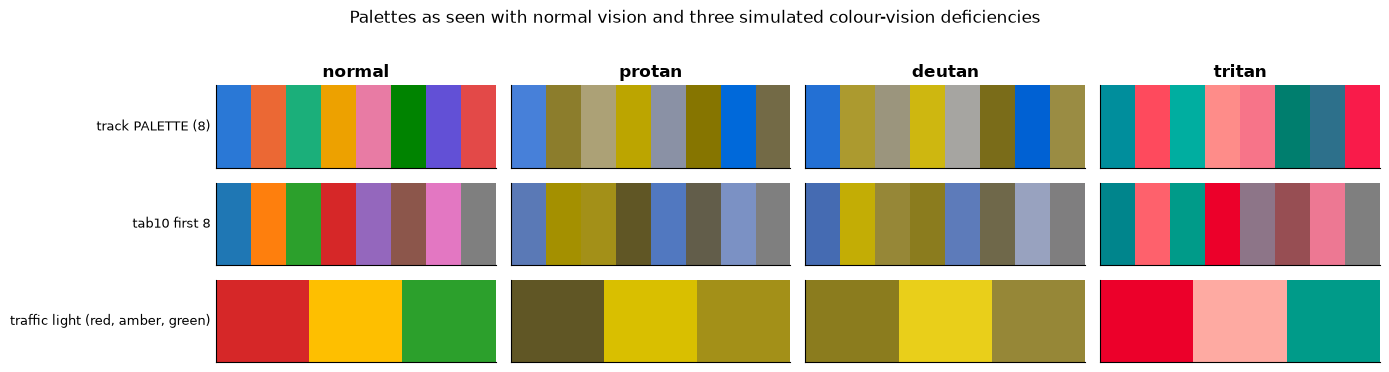

In [10]:
def palette_report(colors, name, pairs="adjacent"):
    """Smallest ΔE between colour pairs ('adjacent' neighbours, or 'all' pairs) for each type of vision."""
    rows = {}
    idx = [(i, i + 1) for i in range(len(colors) - 1)] if pairs == "adjacent" else \
          [(i, j) for i in range(len(colors)) for j in range(i + 1, len(colors))]
    for vision in CVD:
        lab = oklab_of(colors, vision)
        rows[vision] = min(100 * np.linalg.norm(lab[i] - lab[j]) for i, j in idx)
    return pd.Series(rows, name=name)

palettes = {
    "track PALETTE (8)": PALETTE,
    "tab10 first 8": [mpl.colors.to_hex(c) for c in plt.get_cmap("tab10").colors[:8]],
    "traffic light (red, amber, green)": ["#d62728", "#ffbf00", "#2ca02c"],
}
report = pd.DataFrame([palette_report(c, n) for n, c in palettes.items()]).round(1)
print("Worst ADJACENT-pair ΔE (OKLab x100); >= 8 comfortable, < 6 risky:")
print(report)
print("\nWorst pair among ALL pairs (matters for scatter plots and maps, where any two colours can meet):")
print(pd.DataFrame([palette_report(c[:3], n + " - first 3", "all") for n, c in palettes.items()]).round(1))

fig, axes = plt.subplots(len(palettes), 4, figsize=(14, 3.6))
for r, (name, cols) in enumerate(palettes.items()):
    for c, vision in enumerate(CVD):
        lin = np.clip(srgb_to_linear([to_rgb(h) for h in cols]) @ CVD[vision].T, 0, 1)
        srgb = np.where(lin <= 0.0031308, 12.92 * lin, 1.055 * lin ** (1 / 2.4) - 0.055)   # back to display sRGB
        axes[r, c].imshow(srgb[None, :, :], aspect="auto")
        axes[r, c].set(xticks=[], yticks=[]); axes[r, c].grid(False)
        if r == 0:
            axes[r, c].set_title(vision)
    axes[r, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("Palettes as seen with normal vision and three simulated colour-vision deficiencies", y=1.02)
plt.tight_layout(); plt.show()

**What just happened?** Read the tables and the swatches:
- `tab10` in its default order puts **orange next to green**; under the protan simulation that adjacent pair almost vanishes (ΔE below 1; compare the two olive swatches in the protan column). Ordering matters: the same colours in another order can avoid it.
- In the traffic-light palette the neighbours (red–amber, amber–green) survive, but in the **all-pairs** table red vs green collapses under the deutan simulation. That is why "red = bad, green = good" must always come with an **icon or label**.
- The track palette was chosen and ordered so that neighbouring colours stay apart (ΔE about 9 or more) under the common protan and deutan deficiencies. Its weakest case is the very rare tritan type (ΔE 5.8), another reason to add direct labels when a chart has many series. With all pairs in play, use at most the first three colours (scatter plots, maps) and fold the rest into "Other" or small multiples.

### 4.3 Contrast against the background

Thin lines and small text need enough **contrast** with the background. The WCAG 2.x contrast ratio is $\frac{L_1 + 0.05}{L_2 + 0.05}$ with $L$ the relative luminance $0.2126R + 0.7152G + 0.0722B$ of the **linear** RGB values. WCAG asks for **4.5:1** for normal text and **3:1** for large text and essential graphical objects. A colour below 3:1 can still be used for a series if the series also has a visible label.

Contrast of each palette colour against white:
#2a78d6    4.42
#eb6834    3.20
#1baf7a    2.82
#eda100    2.17
#e87ba4    2.69
#008300    4.95
#6250d6    5.77
#e34948    3.95
Below 3:1 (use with direct labels): ['#1baf7a', '#eda100', '#e87ba4']


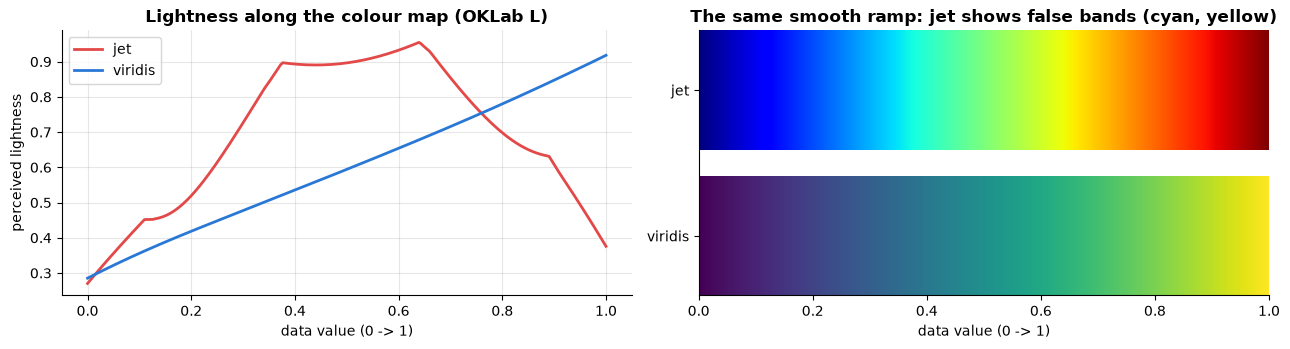

In [11]:
def relative_luminance(hex_color):
    r, g, b = srgb_to_linear(to_rgb(hex_color))
    return 0.2126 * r + 0.7152 * g + 0.0722 * b

def contrast_ratio(c1, c2):
    l1, l2 = sorted([relative_luminance(c1), relative_luminance(c2)], reverse=True)
    return (l1 + 0.05) / (l2 + 0.05)

assert np.isclose(contrast_ratio("#000000", "#ffffff"), 21.0)
bg = "#ffffff"
cr = pd.Series({h: contrast_ratio(h, bg) for h in PALETTE}).round(2)
print("Contrast of each palette colour against white:")
print(cr.to_string())
print("Below 3:1 (use with direct labels):", list(cr[cr < 3].index))

# Lightness profile of colour maps (the rainbow problem from Section 3.4)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
t = np.linspace(0, 1, 256)
for name, col in [("jet", PALETTE[7]), ("viridis", PALETTE[0])]:
    rgb = plt.get_cmap(name)(t)[:, :3]
    L = linear_to_oklab(srgb_to_linear(rgb))[:, 0]
    axes[0].plot(t, L, color=col, label=name)
axes[0].set(title="Lightness along the colour map (OKLab L)", xlabel="data value (0 -> 1)", ylabel="perceived lightness"); axes[0].legend()
ramp = np.tile(np.linspace(0, 1, 256), (10, 1))                          # perfectly smooth data, 0 -> 1
axes[1].imshow(ramp, aspect="auto", cmap="jet", extent=[0, 1, 1.1, 2])
axes[1].imshow(ramp, aspect="auto", cmap="viridis", extent=[0, 1, 0, 0.9])
axes[1].set(ylim=(0, 2), yticks=[0.45, 1.55], yticklabels=["viridis", "jet"], xlabel="data value (0 -> 1)",
            title="The same smooth ramp: jet shows false bands (cyan, yellow)")
axes[1].grid(False)
plt.tight_layout(); plt.show()

**What just happened?** Three of the eight palette colours (the lighter aqua, yellow and pink) are below 3:1 on white: fine for filled bars, but lines and small markers in these colours need direct labels. The lightness curves show the rainbow problem directly: `jet` goes up, down and up again, so equal steps in the data do not look like equal steps; `viridis` rises steadily.

> ⚠️ **Common mistake:** a **sequential** map (light → dark) for data with a meaningful midpoint, such as growth that can be negative, or a **diverging** map for data that are only positive. Pick the scale type by the data, and centre a diverging map on the meaningful value (0, the target).

> 🎓 **Exam / interview tip:** "How do you make a chart accessible?" → colour-blind-safe palette (checked, not guessed), never colour alone (labels, icons, patterns), sufficient contrast, direct labels, alt text or a table view, and readable font sizes.

---
## 5. Annotation and narrative

> 💬 **In plain English:** say the message in the title, colour only what matters, and plan the whole story before drawing.

### 5.1 Titles that state the insight, highlighting, direct labels
A chart for a decision-maker answers one question. Put the **answer in the title** ("action title" or "headline"), highlight the data that support it, and grey out the rest. Replace legends by **direct labels** at the end of lines so the reader does not have to look back and forth.

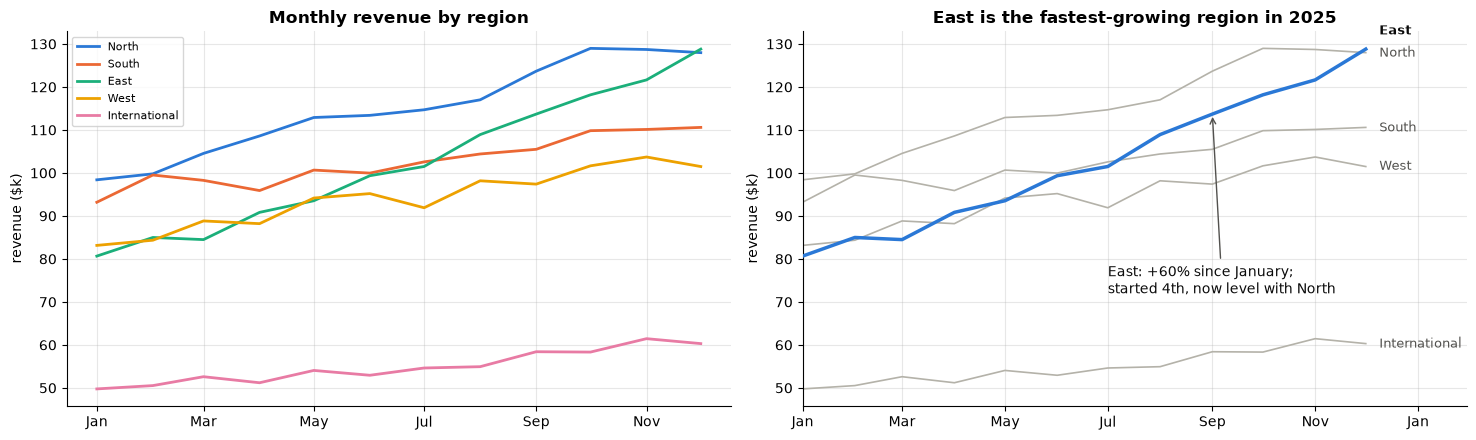

In [12]:
rng = np.random.default_rng(5)
months = pd.date_range("2025-01-01", periods=12, freq="MS")
regions = {"North": 100, "South": 95, "East": 80, "West": 85, "International": 50}
growth = {"North": 0.025, "South": 0.015, "East": 0.045, "West": 0.02, "International": 0.016}
series = {r: base * (1 + growth[r]) ** np.arange(12) * (1 + rng.normal(0, 0.02, 12)) for r, base in regions.items()}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for i, (r, ys) in enumerate(series.items()):
    axes[0].plot(months, ys, color=PALETTE[i], label=r)
axes[0].set(title="Monthly revenue by region", ylabel="revenue ($k)"); axes[0].legend(fontsize=8)
ends = sorted(((ys[-1], r) for r, ys in series.items()))
label_y, last = {}, -np.inf
for y_end, r in ends:                                   # push labels apart so they never overlap
    label_y[r] = max(y_end, last + 5); last = label_y[r]
for r, ys in series.items():
    hi = r == "East"
    axes[1].plot(months, ys, color=PALETTE[0] if hi else GREY, lw=2.5 if hi else 1.2, zorder=3 if hi else 2)
    axes[1].text(months[-1] + pd.Timedelta(days=8), label_y[r], r, va="center", fontsize=9,
                 color=INK if hi else MUTED, fontweight="bold" if hi else "normal")
e = series["East"]
axes[1].annotate(f"East: +{100 * (e[-1] / e[0] - 1):.0f}% since January;\nstarted 4th, now level with North",
                 xy=(months[8], e[8]), xytext=(months[6], 72), arrowprops={"arrowstyle": "->", "color": MUTED}, color=INK)
axes[1].set(title="East is the fastest-growing region in 2025", ylabel="revenue ($k)")
axes[1].set_xlim(months[0], months[-1] + pd.Timedelta(days=60))
for ax in axes:
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b"))
plt.tight_layout(); plt.show()

**What just happened?** The left chart is "spaghetti": five colours, a legend, and a topic title; the reader must discover the message. The right chart says the message in the title, colours only the line that matters, labels lines directly, and adds one annotation with the number. Same data, five seconds instead of thirty.

### 5.2 Small multiples
When many series overlap, split them into a grid of small charts with the **same axes** ("small multiples", Tufte). Each panel can highlight its own series against the others in grey, so comparisons stay easy.

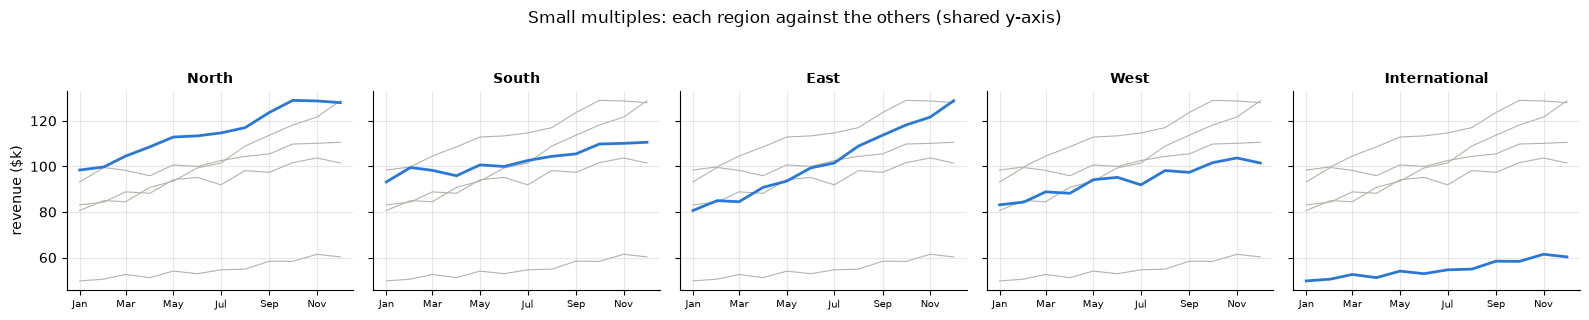

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3), sharey=True)
for ax, (r, ys) in zip(axes, series.items()):
    for other, ys2 in series.items():
        if other != r:
            ax.plot(months, ys2, color=GREY, lw=0.8)
    ax.plot(months, ys, color=PALETTE[0], lw=2)
    ax.set_title(r, fontsize=10)
    ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b")); ax.tick_params(axis="x", labelsize=7)
axes[0].set_ylabel("revenue ($k)")
fig.suptitle("Small multiples: each region against the others (shared y-axis)", y=1.05)
plt.tight_layout(); plt.show()

### 5.3 The Big Idea and the storyboard

From Cole Nussbaumer Knaflic's *Storytelling with Data* (2015), building on Nancy Duarte's work:

1. **Who** is the audience and **what do you want them to do**? (approve a budget, change a price, stop a programme)
2. **The Big Idea**: one complete sentence that (a) states your point of view and (b) says what is at stake. *"Growth comes from more customers, not bigger baskets, so next year's budget should fund acquisition and fix marketplace returns, which cost us X."*
3. **The 3-minute story**: could you tell it without slides?
4. **Storyboard** on paper before any chart: one box per slide, in the order **context → finding → implication → recommendation**.

```
 [1 Context]        [2 Finding]           [3 Finding]           [4 Risk]              [5 Ask]
 Revenue +36%  ->   driven by customers ->  Garden leads, Bedding -> marketplace returns -> fund acquisition,
 like for like      not basket size         lags                  3x other channels      fix returns, drop
                                                                                          the loyalty claim
```

Each chart then gets a **headline** that states its finding, and the deck reads as a story from the headlines alone (the "horizontal logic" used by consultants).

---
## 6. Visualising uncertainty

> 💬 **In plain English:** numbers are never exact; show how sure you are with bars, bands and possible futures.

Every estimate has uncertainty; hiding it makes decisions overconfident. The main tools:

| Tool | Shows | Watch out |
|---|---|---|
| **Error bars** | ±SD, ±SE, or a 95% CI around a point | **always say which one**; SD describes the data spread, SE/CI the precision of the mean |
| **Interval band** | a CI or prediction interval along a line | a CI for the mean line is much narrower than a prediction interval for new points |
| **Fan chart** | nested quantile bands of a forecast (e.g. 50%, 80%, 95%) | bands widen with the horizon; used by central banks (Bank of England since 1996) |
| **Hypothetical outcome plots (HOPs)** | several random draws from the uncertainty, shown one after another (animation) or as a grid | lets non-experts *feel* the uncertainty (Hullman, Resnick & Adar, 2015) |
| Quantile dot plots, gradient plots | discrete or shaded representation of a distribution | good for "chance it is above X" questions |

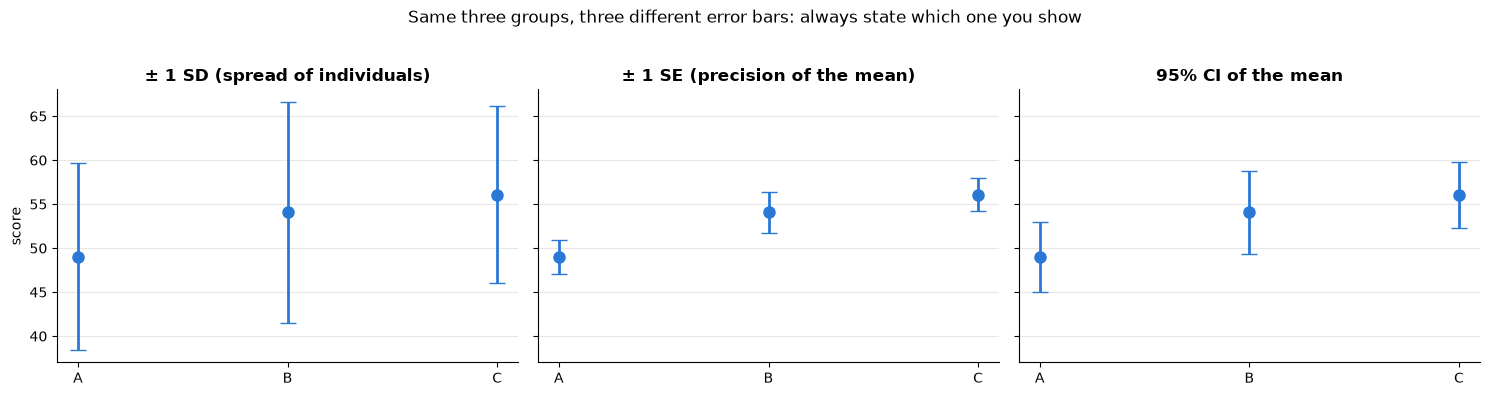

    mean     SD    SE  95% CI half-width
A  49.02  10.60  1.94               3.96
B  54.05  12.58  2.30               4.70
C  56.09  10.04  1.83               3.75


In [14]:
rng = np.random.default_rng(8)
groups = {"A": rng.normal(50, 10, 30), "B": rng.normal(55, 10, 30), "C": rng.normal(53, 10, 30)}
m = np.array([g.mean() for g in groups.values()])
sd = np.array([g.std(ddof=1) for g in groups.values()])
se = sd / np.sqrt(30)
ci = stats.t.ppf(0.975, 29) * se                    # t critical value for n - 1 = 29 df
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, err, title in [(axes[0], sd, "± 1 SD (spread of individuals)"), (axes[1], se, "± 1 SE (precision of the mean)"),
                       (axes[2], ci, "95% CI of the mean")]:
    ax.errorbar(list(groups), m, yerr=err, fmt="o", color=PALETTE[0], capsize=6, ms=8, lw=2)
    ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("score")
fig.suptitle("Same three groups, three different error bars: always state which one you show", y=1.03)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"mean": m, "SD": sd, "SE": se, "95% CI half-width": ci}, index=list(groups)).round(2))

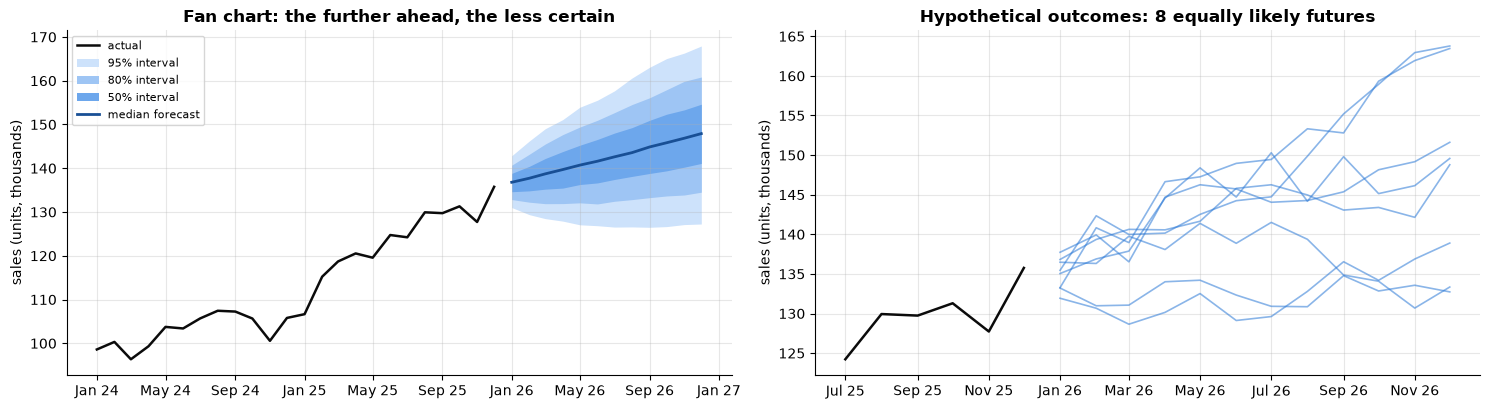

Chance that sales in 12 months exceed today's level + 15: 38% (the median forecast is +12.2)


In [15]:
# Fan chart: 2,000 simulated paths of a monthly sales forecast (random walk with drift)
rng = np.random.default_rng(9)
hist_m = pd.date_range("2024-01-01", periods=24, freq="MS")
hist_y = 100 + np.cumsum(rng.normal(1.0, 3.0, 24))
fut_m = pd.date_range(hist_m[-1] + pd.offsets.MonthBegin(), periods=12, freq="MS")
paths = hist_y[-1] + np.cumsum(rng.normal(1.0, 3.0, (2000, 12)), axis=1)
qs = {q: np.percentile(paths, q, axis=0) for q in [2.5, 10, 25, 50, 75, 90, 97.5]}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]
ax.plot(hist_m, hist_y, color=INK, lw=1.8, label="actual")
for (lo, hi), shade in zip([(2.5, 97.5), (10, 90), (25, 75)], [SEQ_BLUE[0], SEQ_BLUE[1], SEQ_BLUE[2]]):
    ax.fill_between(fut_m, qs[lo], qs[hi], color=shade, lw=0, label=f"{hi - lo:.0f}% interval")
ax.plot(fut_m, qs[50], color=SEQ_BLUE[5], lw=2, label="median forecast")
ax.set(title="Fan chart: the further ahead, the less certain", ylabel="sales (units, thousands)")
ax.legend(fontsize=8, loc="upper left")
# HOPs as a static grid: each panel is one equally likely future
ax = axes[1]
for i in range(8):
    ax.plot(fut_m, paths[i], color=PALETTE[0], alpha=0.55, lw=1.2)        # one colour: the futures are not categories
ax.plot(hist_m[-6:], hist_y[-6:], color=INK, lw=1.8)
ax.set(title="Hypothetical outcomes: 8 equally likely futures", ylabel="sales (units, thousands)")
for a in axes:
    a.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %y"))
plt.tight_layout(); plt.show()
p_above = (paths[:, -1] > hist_y[-1] + 15).mean()
print(f"Chance that sales in 12 months exceed today's level + 15: {100 * p_above:.0f}% "
      f"(the median forecast is +{qs[50][-1] - hist_y[-1]:.1f})")

**What just happened?** The three error-bar panels show the same data with very different bar lengths: an unlabelled error bar is uninterpretable. The fan chart shows how uncertainty grows with the forecast horizon, and the hypothetical-outcome view shows the same uncertainty as concrete possible futures, which non-experts often understand better than a band. A probability statement ("about X% chance of exceeding ...") is often the most useful sentence for a decision-maker.

> ⚠️ **Common mistake:** concluding "no significant difference" because two 95% CIs overlap. Two CIs can overlap by up to about a quarter of their length while the difference is still significant at 5%. Test or plot the **difference** with its own CI.

---
## 7. A KPI dashboard with Plotly, and the BI-tool equivalents

> 💬 **In plain English:** a dashboard is a one-page answer to the questions a person asks every week.

A **dashboard** is a page that answers the **recurring** questions of one audience at a glance. A widely used layout pattern:

```
 ┌────────────┬────────────┬────────────┬────────────┐
 │  KPI tile  │  KPI tile  │  KPI tile  │  KPI tile  │   row 1: the headline numbers with change vs last period
 ├────────────┴────────────┴─────┬──────┴────────────┤
 │  trend over time (line)       │  breakdown (bars) │   row 2: why the KPIs moved
 ├───────────────────────────────┴───────────────────┤
 │  detail table / drill-down                         │   row 3: details for those who need them
 └────────────────────────────────────────────────────┘
```

Readers scan top-left first (an "F"/"Z" reading pattern), so the most important number goes there. Rules: 4–6 KPIs, each with a comparison (vs last year, vs target), consistent colours per entity, filters in one row at the top, and no decoration.

We build it with **Plotly** (interactive: hover, zoom) and export a single self-contained HTML file that opens in any browser, offline. The data are the like-for-like KPIs from the [stakeholder EDA report](11_industry_eda_report_for_stakeholders.ipynb) (copied from its outputs).

In [16]:
import plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display

# Findings of 11_industry_eda_report_for_stakeholders (like-for-like window 1 Jan - 15 Dec)
kpi = pd.DataFrame({"2024": [1335696.0, 10739, 130.9, 3142, 5.0], "2025": [1811234.6, 14920, 127.3, 4013, 4.6]},
                   index=["Net revenue ($)", "Orders", "AOV ($)", "Active customers", "Return rate (%)"])
by_channel = pd.DataFrame({"net_revenue_k": [862.8, 565.9, 382.5], "yoy_growth_pct": [27.3, 45.6, 42.0],
                           "return_rate_pct": [3.2, 3.2, 9.5]}, index=["web", "app", "marketplace"])
by_category = pd.DataFrame({"net_revenue_k": [451.6, 437.5, 345.8, 261.5, 188.6, 126.3],
                            "yoy_growth_pct": [35.0, 69.8, 36.8, 19.8, 7.5, 30.0]},
                           index=["Lighting", "Garden", "Kitchen", "Furniture", "Bedding", "Decor"])
retention = pd.DataFrame({"2024 cohorts": [30.7, 23.9, 20.4, 11.7, 5.7], "2025 cohorts": [31.3, 25.9, 22.8, 13.5, np.nan]},
                         index=[1, 2, 3, 6, 12])   # % of a cohort buying N months after signup
print("plotly", plotly.__version__)
print(kpi.assign(change_pct=(100 * (kpi["2025"] / kpi["2024"] - 1)).round(1)))

plotly 7.1.0
                       2024       2025  change_pct
Net revenue ($)   1335696.0  1811234.6        35.6
Orders              10739.0    14920.0        38.9
AOV ($)               130.9      127.3        -2.8
Active customers     3142.0     4013.0        27.7
Return rate (%)         5.0        4.6        -8.0


In [17]:
CH_COLOR = {"web": PALETTE[0], "app": PALETTE[1], "marketplace": PALETTE[2]}   # colour follows the entity
fig = make_subplots(
    rows=3, cols=4,
    specs=[[{"type": "indicator"}] * 4,
           [{"type": "xy", "colspan": 2}, None, {"type": "xy", "colspan": 2}, None],
           [{"type": "table", "colspan": 4}, None, None, None]],
    row_heights=[0.22, 0.48, 0.30], vertical_spacing=0.08,
    subplot_titles=["", "", "", "", "Retention: share of a cohort buying N months after signup (%)",
                    "Return rate by channel (%)", ""])
tiles = [("Net revenue", kpi.loc["Net revenue ($)"], "$", ",.0f", True, True),
         ("Active customers", kpi.loc["Active customers"], "", ",.0f", True, True),
         ("Average order value", kpi.loc["AOV ($)"], "$", ",.1f", True, True),
         ("Return rate (%)", kpi.loc["Return rate (%)"], "", ".1f", False, False)]   # a rate: change in points
for i, (name, row, prefix, fmt, up_is_good, relative) in enumerate(tiles):
    fig.add_trace(go.Indicator(
        mode="number+delta", value=row["2025"], number={"prefix": prefix, "valueformat": fmt},
        delta={"reference": row["2024"], "relative": relative, "valueformat": ".1%" if relative else "+.1f",
               "suffix": "" if relative else " pts",
               "increasing": {"color": "#0ca30c" if up_is_good else "#d03b3b"},
               "decreasing": {"color": "#d03b3b" if up_is_good else "#0ca30c"}},
        title={"text": f"{name}<br><span style='font-size:11px;color:{MUTED}'>2025 vs 2024, like for like</span>"}),
        row=1, col=i + 1)
for j, col in enumerate(retention.columns):
    fig.add_trace(go.Scatter(x=retention.index, y=retention[col], mode="lines+markers", name=col,
                             line={"color": [GREY, PALETTE[0]][j], "width": 2}, marker={"size": 8},
                             hovertemplate="month %{x}: %{y:.1f}%<extra>" + col + "</extra>"), row=2, col=1)
fig.add_trace(go.Bar(x=by_channel.index, y=by_channel["return_rate_pct"], showlegend=False,
                     marker_color=[CH_COLOR[c] for c in by_channel.index],
                     text=[f"{v:.1f}%" for v in by_channel["return_rate_pct"]], textposition="outside",
                     hovertemplate="%{x}: %{y:.1f}% of gross sales returned<extra></extra>"), row=2, col=3)
fig.add_trace(go.Table(
    header={"values": ["Category", "Net revenue 2025 ($k)", "Growth vs 2024 (%)"], "fill_color": "#f0efec", "align": "left"},
    cells={"values": [by_category.index, by_category["net_revenue_k"], by_category["yoy_growth_pct"]], "align": "left"}),
    row=3, col=1)
fig.update_xaxes(title_text="months after signup", row=2, col=1)
fig.update_yaxes(range=[0, 12], row=2, col=3)
fig.update_layout(height=820, width=1100, template="plotly_white", font={"family": "Arial", "size": 12},
                  title={"text": "NordHome sales dashboard: 2025 (1 Jan - 15 Dec) vs same period 2024"},
                  legend={"orientation": "h", "x": 0.0, "y": 0.66}, margin={"t": 90, "l": 40, "r": 40, "b": 30})

html_path = os.path.join(WORK, "kpi_dashboard.html")
fig.write_html(html_path, include_plotlyjs=True, full_html=True)      # self-contained: works offline, no CDN
print(f"Dashboard written: {os.path.basename(html_path)} ({os.path.getsize(html_path) / 1e6:.1f} MB, plotly.js embedded)")
html_text = open(html_path, encoding="utf-8").read()
assert "Plotly.newPlot" in html_text and "Return rate by channel" in html_text
display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False)))  # interactive preview in Jupyter (needs the CDN when viewed)

Dashboard written: kpi_dashboard.html (4.8 MB, plotly.js embedded)


The interactive preview above needs a browser with internet access to load plotly.js; the **exported file** embeds plotly.js and works offline. For readers of the saved notebook (for example on GitHub, which does not run JavaScript), here is the same layout as a static image:

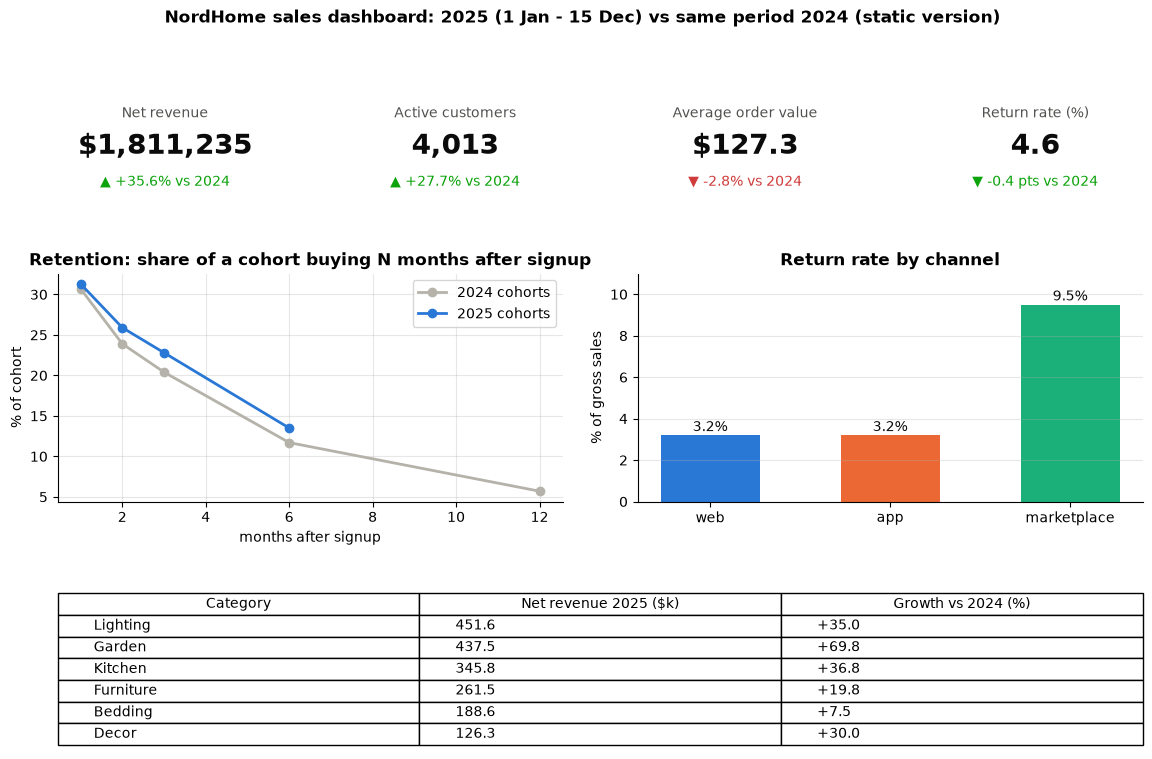

In [18]:
fig = plt.figure(figsize=(14, 8.5))
gs = fig.add_gridspec(3, 4, height_ratios=[0.8, 2, 1.4], hspace=0.55, wspace=0.35)
for i, (name, row, prefix, fmt, up_is_good, relative) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    change = row["2025"] / row["2024"] - 1 if relative else row["2025"] - row["2024"]
    good = (change > 0) == up_is_good
    delta_txt = f"{100 * change:+.1f}% vs 2024" if relative else f"{change:+.1f} pts vs 2024"
    val = f"{prefix}{row['2025']:{fmt}}"
    ax.text(0.5, 0.75, name, ha="center", fontsize=10, color=MUTED)
    ax.text(0.5, 0.35, val, ha="center", fontsize=20, fontweight="bold", color=INK)
    ax.text(0.5, 0.0, f"{'▲' if change > 0 else '▼'} {delta_txt}", ha="center", fontsize=10,
            color="#0ca30c" if good else "#d03b3b")
ax = fig.add_subplot(gs[1, :2])
for j, col in enumerate(retention.columns):
    ax.plot(retention.index, retention[col], "o-", color=[GREY, PALETTE[0]][j], label=col)
ax.set(title="Retention: share of a cohort buying N months after signup", xlabel="months after signup", ylabel="% of cohort")
ax.legend()
ax = fig.add_subplot(gs[1, 2:])
ax.bar(by_channel.index, by_channel["return_rate_pct"], color=[CH_COLOR[c] for c in by_channel.index], width=0.55)
for i, v in enumerate(by_channel["return_rate_pct"]):
    ax.text(i, v + 0.2, f"{v:.1f}%", ha="center", color=INK)
ax.set(title="Return rate by channel", ylabel="% of gross sales", ylim=(0, 11)); ax.grid(axis="x", visible=False)
ax = fig.add_subplot(gs[2, :]); ax.axis("off")
tbl = ax.table(cellText=[[c, f"{r.net_revenue_k:.1f}", f"{r.yoy_growth_pct:+.1f}"] for c, r in by_category.iterrows()],
               colLabels=["Category", "Net revenue 2025 ($k)", "Growth vs 2024 (%)"], loc="center", cellLoc="left")
tbl.scale(1, 1.3)
fig.suptitle("NordHome sales dashboard: 2025 (1 Jan - 15 Dec) vs same period 2024 (static version)", fontweight="bold")
plt.show()

### Power BI and Tableau: the same ideas, different tools

| Concept | In this notebook | Power BI | Tableau |
|---|---|---|---|
| Data model / semantic layer | pandas tables | data model (star schema), relationships | data source, relationships / logical layer |
| Calculated metric | `kpi` computations | **measures** written in DAX (e.g. `Net Revenue = SUM(Sales[Amount]) - SUM(Returns[Amount])`) | calculated fields, LOD expressions |
| Time comparison | like-for-like window by hand | time-intelligence functions (`SAMEPERIODLASTYEAR`) | table calculations, date functions |
| KPI tile | `go.Indicator` | Card / KPI visual | big-number text sheet / KPI |
| Filters | (Plotly dropdowns, or Dash) | slicers, filter pane, cross-filtering between visuals | filters, parameters, dashboard actions |
| Drill-down | detail table | drill-through pages, hierarchies | drill-down hierarchies, tooltips with sheets |
| Access control | — | row-level security (RLS) | user filters / row-level security |
| Refresh and sharing | re-run the notebook, send the HTML | Power BI service, scheduled refresh, apps | Tableau Server/Cloud, extracts refresh |

The design rules of Sections 1–6 apply unchanged in any tool: one message per visual, honest axes, colour by job, uncertainty shown, and a layout that follows the reader's questions. Python dashboards that need filters and callbacks are usually built with **Dash** or **Streamlit** on top of the same Plotly figures.

---
## 8. Industry mini-case: a 5-chart executive story

> 💬 **In plain English:** turn a finished analysis into five charts that lead a busy manager to a decision.

**Brief.** The head of sales of "NordHome" (the retailer of the [stakeholder EDA report](11_industry_eda_report_for_stakeholders.ipynb)) has 10 minutes in the leadership meeting. The analysis is done; we must turn its findings into **five charts** that tell one story.

**Audience and action:** leadership; decide next year's budget priorities.

**Big Idea:** *"2025 growth (+35.6% like for like) came from more customers, not bigger baskets; to keep it going, fund customer acquisition and fix marketplace returns, and do not credit the loyalty programme with the members' higher spend."*

**Storyboard (one finding per chart, the headline is the finding):**
1. Growth is strong and real (like for like).
2. It comes from more customers and more orders per customer, not from basket size.
3. Garden and Lighting carry it; Bedding lags.
4. Marketplace returns are 3 times those of other channels.
5. The loyalty "+19%" is selection, not programme impact.

All numbers below are the outputs of notebook 11 (copied, not recomputed).

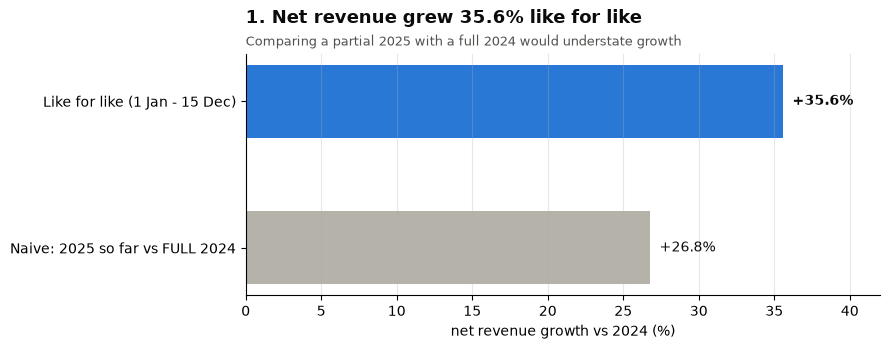

In [19]:
def headline(ax, text, sub=None):
    """Action title (the finding) + a smaller subtitle (what is plotted)."""
    ax.set_title(text, loc="left", fontsize=13, fontweight="bold", color=INK, pad=22)
    if sub:
        ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=MUTED, va="bottom")

change = 100 * (kpi["2025"] / kpi["2024"] - 1)

# Chart 1: like-for-like growth, with the naive comparison as context
fig, ax = plt.subplots(figsize=(9, 3.6))
vals = pd.Series({"Naive: 2025 so far vs FULL 2024": 26.8, "Like for like (1 Jan - 15 Dec)": change["Net revenue ($)"]})
ax.barh(vals.index, vals.to_numpy(), color=[GREY, PALETTE[0]], height=0.5)
for i, v in enumerate(vals):
    ax.text(v + 0.6, i, f"+{v:.1f}%", va="center", color=INK, fontweight="bold" if i == 1 else "normal")
ax.set(xlim=(0, 42), xlabel="net revenue growth vs 2024 (%)"); ax.grid(axis="y", visible=False)
headline(ax, f"1. Net revenue grew {change['Net revenue ($)']:.1f}% like for like",
         "Comparing a partial 2025 with a full 2024 would understate growth")
plt.tight_layout(); plt.show()

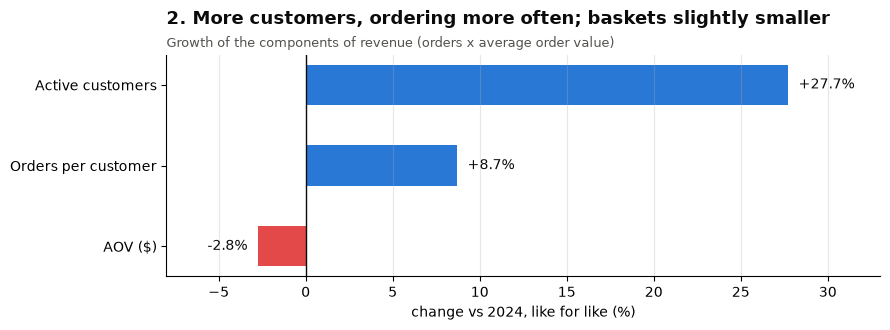

Active customers       27.7
Orders per customer     8.7
AOV ($)                -2.8
dtype: float64


In [20]:
# Chart 2: decomposition of the change (diverging bars around 0; neutral grey for the baseline)
# 'Orders per customer' is notebook 11's KPI (orders by KNOWN customers / active customers): +8.7%.
# (Total orders / customers would give a slightly different number, because guest orders have no customer id.)
drivers = pd.Series({"Active customers": change["Active customers"], "Orders per customer": 8.7, "AOV ($)": change["AOV ($)"]})
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [PALETTE[0] if v > 0 else "#e34948" for v in drivers]
ax.barh(drivers.index[::-1], drivers.to_numpy()[::-1], color=colors[::-1], height=0.5)
ax.axvline(0, color=INK, lw=1)
for i, v in enumerate(drivers.to_numpy()[::-1]):
    ax.text(v + (0.6 if v > 0 else -0.6), i, f"{v:+.1f}%", va="center", ha="left" if v > 0 else "right", color=INK)
ax.set(xlim=(-8, 33), xlabel="change vs 2024, like for like (%)"); ax.grid(axis="y", visible=False)
headline(ax, "2. More customers, ordering more often; baskets slightly smaller",
         "Growth of the components of revenue (orders x average order value)")
plt.tight_layout(); plt.show()
print(drivers.round(1))

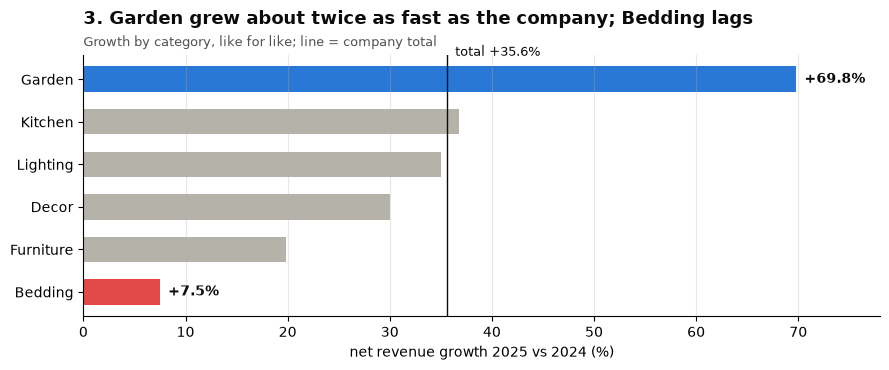

In [21]:
# Chart 3: category growth vs the total, highlight leader and laggard
total_g = change["Net revenue ($)"]
g = by_category["yoy_growth_pct"].sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
col = [PALETTE[0] if c == "Garden" else ("#e34948" if c == "Bedding" else GREY) for c in g.index]
ax.barh(g.index, g.to_numpy(), color=col, height=0.6)
ax.axvline(total_g, color=INK, lw=1)
ax.text(total_g + 0.8, len(g) - 0.45, f"total +{total_g:.1f}%", color=INK, fontsize=9)
for i, (c, v) in enumerate(g.items()):
    if c in ("Garden", "Bedding"):
        ax.text(v + 0.8, i, f"+{v:.1f}%", va="center", color=INK, fontweight="bold")
ax.set(xlabel="net revenue growth 2025 vs 2024 (%)", xlim=(0, 78)); ax.grid(axis="y", visible=False)
headline(ax, "3. Garden grew about twice as fast as the company; Bedding lags",
         "Growth by category, like for like; line = company total")
plt.tight_layout(); plt.show()

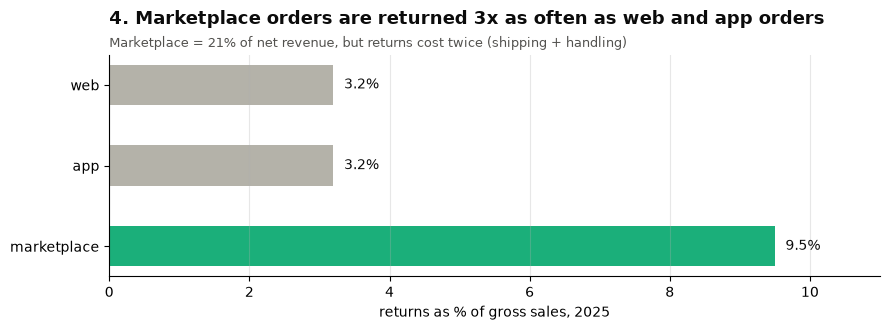

In [22]:
# Chart 4: marketplace return rate vs other channels (colour = channel identity, same as in the dashboard)
rr = by_channel["return_rate_pct"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(rr.index[::-1], rr.to_numpy()[::-1], color=[CH_COLOR[c] if c == "marketplace" else GREY for c in rr.index[::-1]], height=0.5)
for i, v in enumerate(rr.to_numpy()[::-1]):
    ax.text(v + 0.15, i, f"{v:.1f}%", va="center", color=INK)
ax.set(xlabel="returns as % of gross sales, 2025", xlim=(0, 11)); ax.grid(axis="y", visible=False)
ratio = rr["marketplace"] / rr[["web", "app"]].mean()
headline(ax, f"4. Marketplace orders are returned {ratio:.0f}x as often as web and app orders",
         f"Marketplace = {by_channel.loc['marketplace', 'net_revenue_k'] / by_channel['net_revenue_k'].sum() * 100:.0f}% of net revenue, but returns cost twice (shipping + handling)")
plt.tight_layout(); plt.show()

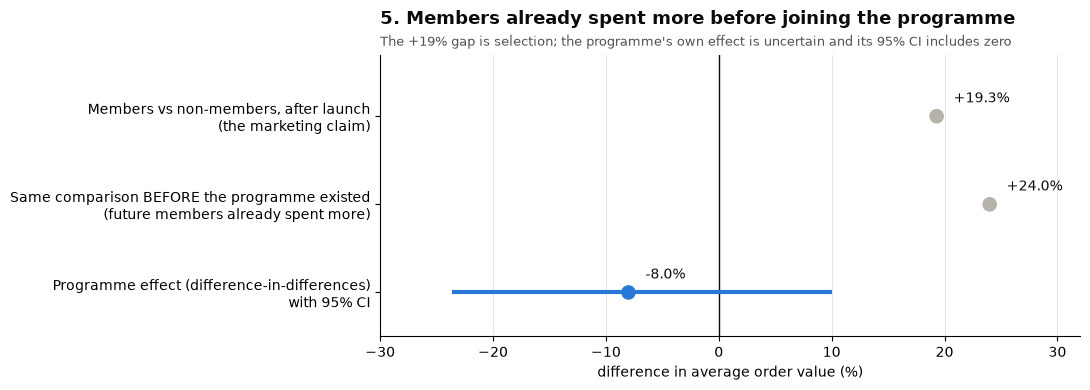

In [23]:
# Chart 5: the loyalty claim. Point estimates WITH uncertainty, and the before/after logic.
claims = pd.DataFrame({
    "estimate": [19.3, 24.0, -8.0],
    "low": [np.nan, np.nan, -23.6], "high": [np.nan, np.nan, 10.0]},
    index=["Members vs non-members, after launch\n(the marketing claim)",
           "Same comparison BEFORE the programme existed\n(future members already spent more)",
           "Programme effect (difference-in-differences)\nwith 95% CI"])
fig, ax = plt.subplots(figsize=(11, 4))
y = np.arange(len(claims))[::-1]
ax.axvline(0, color=INK, lw=1)
ax.scatter(claims["estimate"], y, s=90, color=[GREY, GREY, PALETTE[0]], zorder=3)
ax.hlines(y[2], claims["low"].iloc[2], claims["high"].iloc[2], color=PALETTE[0], lw=3)
for yy, v in zip(y, claims["estimate"]):
    ax.text(v + 1.5, yy + 0.12, f"{v:+.1f}%", ha="left", va="bottom", color=INK, fontsize=10)
ax.set(yticks=y, yticklabels=claims.index, xlim=(-30, 32), ylim=(-0.5, 2.7), xlabel="difference in average order value (%)")
ax.grid(axis="y", visible=False)
headline(ax, "5. Members already spent more before joining the programme",
         "The +19% gap is selection; the programme's own effect is uncertain and its 95% CI includes zero")
plt.tight_layout(); plt.show()

**What just happened?** Five charts, five headlines that read as the story on their own:

1. Net revenue grew **35.6%** like for like (a naive comparison would have said 26.8%).
2. More **customers (+27.7%)** and more **orders per customer (+8.7%)**; average order value **−2.8%**.
3. **Garden +69.8%**, about twice the company rate (+35.6%); **Bedding +7.5%** lags.
4. Marketplace returns **9.5%** of gross sales vs **3.2%** on web and app: **3x**.
5. The loyalty "**+19.3%**" is selection: future members already spent **+24.0%** more before the programme; the difference-in-differences estimate is **−8.0%** with a 95% CI from −23.6% to +10.0%.

Design choices applied: one message per chart and a headline that states it; one highlight colour, everything else grey; the same colour for "marketplace" as in the dashboard; one axis per chart; uncertainty shown where a decision depends on it (chart 5); a context bar (chart 1) to pre-empt the obvious question.

The **closing slide** (text, no chart): *"Recommendation: (1) shift budget to customer acquisition, which drives growth; (2) launch a returns-reduction plan with the marketplace partner; (3) do not cite '+19% from loyalty' and run a randomised test of the programme instead ([design of experiments](14_design_of_experiments.ipynb))."*

---
## 9. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same rules make ML reports, monitoring dashboards and AI-generated charts trustworthy.

- **ML model reports** live or die by visualisation: learning curves with seed bands, calibration plots, confusion matrices with a sequential colour map, and model comparisons with **CIs** rather than bare leaderboard numbers ([model evaluation](../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb), [24_Research_Methods/03](../24_Research_Methods/03_statistical_significance_and_reporting.ipynb)).
- **Explainability** plots (SHAP summaries, partial dependence) follow the same encoding rules ([07_explainability](../03_Machine_Learning/07_explainability/01_explainability.ipynb)).
- **Monitoring dashboards** for ML and LLM systems (drift, latency, cost, quality) use exactly the KPI-tile + trend + breakdown layout of Section 7.
- **LLM-generated charts**: assistants can write plotting code in seconds, which makes the **judgement** in this notebook (right chart, honest axes, accessible colour, a stated message) the human's main contribution, and a checklist to review AI-generated charts against.
- **Uncertainty communication** of forecasts and model predictions (prediction intervals, conformal sets: [conformal prediction](../03_Machine_Learning/14_conformal_prediction/01_conformal_prediction.ipynb)) uses fan charts and interval plots.

## Recap

- Use the **best encoding** for the key comparison: position > length > angle > area > colour (Cleveland–McGill).
- One **pre-attentive** highlight (colour vs grey) points at the message; maximise the **data-ink ratio**.
- Choose the chart from the **question**: comparison, distribution, composition, relationship, change over time, or a single number.
- Bars start at **0**; no **dual axes** (index or split instead); no pies with many slices; scale **areas**, not radii; avoid rainbow maps (lie factor ≈ 1 is honest).
- Colour has three jobs: **categorical** (fixed order, ≤ 8), **sequential** (one hue), **diverging** (two hues + grey midpoint). **Check** CVD separation and contrast; never rely on colour alone.
- Titles state the **insight**; highlight, label directly, use **small multiples**; plan the story with a **Big Idea** and a storyboard.
- Show **uncertainty** (and say which kind): error bars, intervals, fan charts, hypothetical outcomes.
- Dashboards: KPI tiles with comparisons on top, trends and breakdowns below, details last; the same ideas in Power BI/Tableau.

## Practice problems

**1. (Easy, conceptual)** Which chart would you use? (a) the distribution of delivery times for 3 warehouses; (b) monthly website visits over 3 years; (c) market share of 2 companies vs "all others"; (d) whether ad spend relates to sales across 200 stores; (e) "how many active users do we have today?".

<details><summary>Show solution</summary>

(a) box plots or violin/strip plots side by side (or overlaid ECDFs); (b) a line chart; (c) a single 100% stacked bar or, with three parts, a pie is acceptable (or simply the three numbers); (d) a scatter plot with a trend line (hexbin if many points); (e) a stat tile: the number, with the change vs last period.

</details>

**2. (Easy, coding)** Write `lie_factor(shown_start, shown_end, data_start, data_end)` and compute it for a bar chart truncated at 90 that shows the values 92 and 96.

<details><summary>Show solution</summary>

```python
def lie_factor(shown_start, shown_end, data_start, data_end):
    """Tufte's lie factor: relative change shown in the graphic / relative change in the data."""
    shown = (shown_end - shown_start) / shown_start
    data = (data_end - data_start) / data_start
    return shown / data

# a bar chart truncated at 90: values 92 and 96 are drawn as bars of length 2 and 6
print(round(lie_factor(92 - 90, 96 - 90, 92, 96), 1))
```
The bars grow from length 2 to 6 (+200%) while the data grow by 4.3%: lie factor 46.

</details>

**3. (Medium, coding)** Implement the WCAG contrast ratio from hex strings without libraries. Which of `#777777` and `#595959` passes 4.5:1 for text on white?

<details><summary>Show solution</summary>

```python
def srgb_channel_to_linear(c):
    return c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4

def contrast(hex1, hex2):
    def lum(h):
        r, g, b = (int(h.lstrip("#")[i:i + 2], 16) / 255 for i in (0, 2, 4))
        r, g, b = map(srgb_channel_to_linear, (r, g, b))
        return 0.2126 * r + 0.7152 * g + 0.0722 * b
    l1, l2 = sorted([lum(hex1), lum(hex2)], reverse=True)
    return (l1 + 0.05) / (l2 + 0.05)

print(round(contrast("#777777", "#ffffff"), 2), round(contrast("#595959", "#ffffff"), 2))
```
`#777777` gives about 4.48:1, just failing 4.5:1 for normal text; `#595959` gives about 7:1 and passes (even the stricter AAA level of 7:1).

</details>

**4. (Easy, coding)** Replace a dual-axis chart by an index chart: write `index_to_base(df)` that rescales every column to 100 in the first row.

<details><summary>Show solution</summary>

```python
import pandas as pd

def index_to_base(df, base_row=0):
    """Divide every column by its value in base_row and multiply by 100 (common-base index)."""
    return 100 * df / df.iloc[base_row]

df = pd.DataFrame({"users_m": [2.0, 3.0, 5.0], "revenue_musd": [40.0, 44.0, 50.0]}, index=[2024, 2025, 2026])
print(index_to_base(df))
```

</details>

**5. (Easy, coding)** Write `highlight_colors(categories, highlight)` that returns an accent colour for the highlighted categories and grey for the others, to build "one message" bar charts.

<details><summary>Show solution</summary>

```python
def highlight_colors(categories, highlight, accent="#2a78d6", grey="#b4b2a9"):
    """One accent colour for the highlighted categories, grey for all others (same order as input)."""
    hs = set(highlight)
    return [accent if c in hs else grey for c in categories]

print(highlight_colors(["web", "app", "marketplace"], ["marketplace"]))
```

</details>

**6. (Medium, conceptual)** A colleague's slide shows a 3-D exploded pie with 11 product categories in a rainbow of colours, titled "Sales by product". List the problems and redesign it.

<details><summary>Show solution</summary>

Problems: angles/areas are hard to compare (worse with 11 slices); 3-D perspective distorts the front slices (lie factor ≠ 1); exploding adds no information; 11 hues exceed what readers can map and are not colour-blind safe; the title states a topic, not a finding; a legend forces back-and-forth reading. Redesign: a **sorted horizontal bar chart** (or dot plot) of the 11 categories, one colour, the 2–3 categories that matter highlighted and labelled with values, small ones optionally folded into "Other", and an action title such as "Three products make 60% of sales".

</details>

**7. (Medium, coding)** Write `fan_quantiles(paths, levels=(50, 80, 95))` that returns the median and the central intervals for each time step of simulated forecast paths, and check that the bands are nested and widen with the horizon.

<details><summary>Show solution</summary>

```python
import numpy as np

def fan_quantiles(paths, levels=(50, 80, 95)):
    """paths: (n_sims, horizon). Returns {level: (lower, upper)} central intervals per time step, plus the median."""
    out = {"median": np.percentile(paths, 50, axis=0)}
    for lev in levels:
        lo, hi = 50 - lev / 2, 50 + lev / 2
        out[lev] = (np.percentile(paths, lo, axis=0), np.percentile(paths, hi, axis=0))
    return out

rng = np.random.default_rng(0)
paths = np.cumsum(rng.normal(0, 1, (5000, 12)), axis=1)
q = fan_quantiles(paths)
print(np.round(q[95][1][[0, 5, 11]], 2))
```

</details>

**8. (Hard, design)** Sketch (in words or ASCII) a one-page dashboard for an **LLM customer-support assistant** used by a call centre manager. Name the KPIs, comparisons, charts and colour rules.

<details><summary>Show solution</summary>

Row 1 KPI tiles (each vs last week): **resolution rate without human handover**, **customer satisfaction (CSAT)**, **median response latency**, **cost per conversation**, **escalations flagged for safety**. Row 2: a line chart of resolution rate and CSAT over 12 weeks (two panels with their own axes, not a dual axis), with a band showing the weekly 95% CI because daily volumes vary; a sorted bar chart of top 10 intents by volume with resolution rate as dots on a common scale. Row 3: a table of the worst-performing intents with links to example conversations (drill-down). Colour: one accent for "this week", grey for history; status colours (good/warning/critical) only on KPI deltas and always with an arrow/icon and label; colour-blind-checked palette. Filters at the top: date range, channel, language. Title states the week's headline (e.g. "Resolution up 3 points; billing intents still escalate most").

</details>

## Further reading

- E. R. Tufte, *The Visual Display of Quantitative Information*, 2nd ed. (2001): data-ink, chartjunk, lie factor, small multiples.
- W. S. Cleveland & R. McGill (1984), "Graphical Perception: Theory, Experimentation, and Application to the Development of Graphical Methods", *JASA* 79(387).
- C. Nussbaumer Knaflic, *Storytelling with Data* (Wiley, 2015): the Big Idea, storyboarding, decluttering.
- C. O. Wilke, *Fundamentals of Data Visualization* (O'Reilly, 2019), free online at clauswilke.com/dataviz.
- J. Hullman, P. Resnick & E. Adar (2015), "Hypothetical Outcome Plots Outperform Error Bars and Violin Plots for Inferences about Reliability of Variable Ordering", *PLOS ONE*.
- Free: the [Plotly Python documentation](https://plotly.com/python/) and W3C's [WCAG 2.2](https://www.w3.org/TR/WCAG22/) contrast guidance.

## Next notebook

➡️ Continue with the machine-learning module: [03_Machine_Learning/00_start_here_your_first_ml_model.ipynb](../03_Machine_Learning/00_start_here_your_first_ml_model.ipynb), or revisit [12_data_acquisition_apis_scraping_and_formats.ipynb](12_data_acquisition_apis_scraping_and_formats.ipynb) to start the data-science craft sequence again with your own data.

In [24]:
shutil.rmtree(WORK, ignore_errors=True)        # remove the exported dashboard and other temporary files
print("Temporary folder removed:", not os.path.exists(WORK))

Temporary folder removed: True
